## Explore Dataset

In [41]:
import geopandas as gpd
import dotenv
import os
import pandas as pd
import shapely
from google.cloud import storage
from addCSOs import calculate_risk_factors_cso
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
dotenv.load_dotenv()

## Obtaining data

Keeping all the data in the EPSG 3857 coordinate referencing system (CRS) to work better with distances

### CSO Data

In [ ]:
geo_JSON_url = "https://services-eu1.arcgis.com/MSNNjkZ51iVh8yBj/arcgis/rest/services/Northumbrian_Water_Storm_Overflow_Activity_2_view/FeatureServer/0/query?outFields=*&where=1%3D1&f=geojson"
cso: gpd.GeoDataFrame = gpd.read_file(geo_JSON_url)
cso_all = cso.to_crs(epsg=3857)

In [ ]:
INPUT_PATH = os.getenv("CSO_DATA_LOC")
if INPUT_PATH is None:
    raise ValueError("Input Path not set")
bucketName = INPUT_PATH.split("/")[2]
path_in_bucket = '/'.join(INPUT_PATH.split("/")[3:])
storage_client = storage.Client()
bucket = storage_client.get_bucket(bucketName)
geojson_filenames = ["gs://"+bucketName+'/' +
                     fname.name for fname in bucket.list_blobs(prefix=path_in_bucket) if fname.name.endswith('.geojson')]
cso = gpd.read_file(geojson_filenames[-1])
cso_all = cso.to_crs(epsg=3857)

In [ ]:
cso_all

,OBJECTID,id,Site Name,Watercourse Name,Bathing Water Site,Spill Status,Latest Spill Start Time,Latest Spill End Time,Outfall Reference,Rainfall,Bathing Water Site 2,spillStatus,geometry
0,1,6NW000001,Kimberley Gardens SO,Tributary of Twizell Burn,NA,No Recent Spill,2025-01-05 16:29:59,2025-01-06 13:59:59,NZ21512403,None,None,0,POINT (-186072.981 7334254.457)
1,2,6NW000002,Front Street SO 1,Tributary of Stanley Beck,NA,Monitor Offline – Under Maintenance,2024-10-16 23:44:59,2024-10-17 00:44:59,NZ21514101,None,None,-1,POINT (-185593.945 7333616.153)
2,3,6NW000003,Dene Grove SO Brinkburn Dene,Cocker Beck,NA,No Recent Spill,2024-10-09 06:30:00,2024-10-09 08:45:00,NZ27156326,None,None,0,POINT (-175240.482 7271653.761)
3,4,6NW000004,West Park Estate SO,Tributary of Herrington Burn,NA,No Recent Spill,2024-12-02 08:13:59,2024-12-02 08:15:59,NZ3353WC01,None,None,0,POINT (-161066.673 7336871.193)
4,5,6NW000005,Blackett Street Jarrow SO,River Tyne Estuary,NA,No Recent Spill,2025-01-06 11:15:00,2025-01-06 12:30:00,NZ31657802,None,None,0,POINT (-167525.18 7358719.246)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1567,1576,6NW801142(2),Manfield Sewage Disposal Works Network SO Inle...,Tributary of River Tees,NA,No Recent Spill,NaT,NaT,NZ22134501,None,None,0,POINT (-184197.641 7268524.168)
1568,1577,6NW801209,Seventh Avenue SO,River Team,NA,No Recent Spill,2025-01-06 14:14:59,2025-01-06 14:29:59,NZ24596510,None,None,0,POINT (-178992.389 7348032.527)
1569,1578,6NW801356(2),Geneva Road SO,Cree Beck,NA,Monitor Offline – Under Maintenance,2024-10-09 06:29:59,2024-10-09 06:44:59,NZ30126905,None,None,-1,POINT (-170470.041 7268320.644)
1570,1579,6NW000064,Aislaby Road Sewage Pumping Station,River Tees,NA,No Recent Spill,NaT,NaT,NZ41135103,None,None,0,POINT (-151403.976 7267787.657)


### River data

In [ ]:
RIVERS_PATH = os.getenv("RIVERS_PATH")
rivers = gpd.read_file(RIVERS_PATH)
rivers = rivers.to_crs(epsg=3857)
rivers_all = rivers.copy()

### Clip to cso bounds

In [12]:
rivers = rivers_all.clip(cso.total_bounds).explode()

### Clip to Catchment Data

In [38]:
cmnt = gpd.read_file(
    "https://environment.data.gov.uk/catchment-planning/OperationalCatchment/3052.geojson"
    )
cmnt.to_crs(cso.crs,inplace=True)

In [ ]:
rivers = gpd.clip(rivers_all, cmnt)
# Remove all rivers that aren't LineStrings after Clipping
rivers = rivers[rivers.geometry.apply(
    lambda x: isinstance(x, shapely.LineString))]
cso = gpd.clip(cso_all, cmnt)

### Pre Explore

In [18]:
m = cmnt.explore(highlight=False,
                 popup=False,
                 tooltip=False,
                 color="grey")
rivers.explore(m=m)
cso.explore(m=m, marker_kwds={"radius":5},color="red")

## Use addCSOs.py

In [19]:
RIVER_RESOLUTION:float= 50
MAX_OUTFALL_DIST_FROM_RIVER:float = 500
MAX_RISK_DISTANCE: float = 10_000

In [20]:
river_points, cso_with_locations = calculate_risk_factors_cso(
    cso,
    rivers,
    cso_df_id_col="id",
    river_resolution=RIVER_RESOLUTION,
    max_outfall_dist_from_river=MAX_OUTFALL_DIST_FROM_RIVER,
    max_risk_distance=MAX_RISK_DISTANCE,
    include_upstream=False,
    river_directed=True,
)

## Add Risk

In [21]:
def simple_risk(csoInfo: list[tuple])->float:
    tot = 0
    for csoID, dist in csoInfo:
        tot += MAX_RISK_DISTANCE - abs(dist)
    return tot

def add_simple_risk(gdf:gpd.GeoDataFrame)->gpd.GeoSeries:
    return gdf["csoInfo"].apply(simple_risk)

In [22]:
def linear_dist_decrease(d:float)->float:
    return (MAX_RISK_DISTANCE-d)/MAX_RISK_DISTANCE

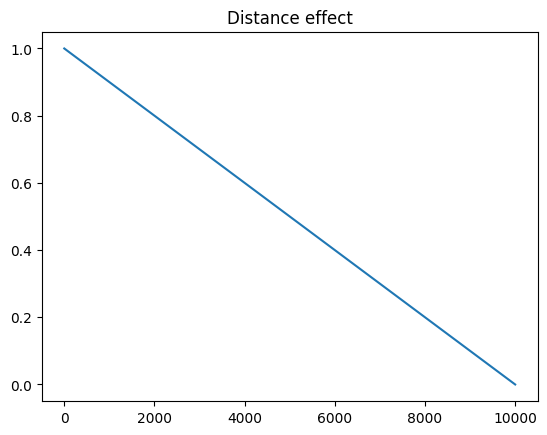

In [45]:
x = np.linspace(0,MAX_RISK_DISTANCE,100)
plt.plot(x,linear_dist_decrease(x))
plt.title("Distance effect")
plt.show()

In [23]:
def add_frequency_risk(gdf:gpd.GeoDataFrame)->gpd.GeoSeries:
    EDM_PATH = os.getenv("CSO_DATA_OUTPUT")
    edm = pd.read_pickle(EDM_PATH)
    freq = edm.groupby("Monitor_ID").count()["Event_Start"]
    return gdf["csoInfo"].apply(lambda x: sum([freq[csoid]*linear_dist_decrease(dist) for csoid, dist in x if csoid in freq.index]))

In [24]:
def add_duration_risk(gdf:gpd.GeoDataFrame)->gpd.GeoSeries:
    EDM_PATH = os.getenv("CSO_DATA_OUTPUT")
    edm = pd.read_pickle(EDM_PATH)
    dur = edm["Event_End"] - edm["Event_Start"]
    duration = dur.groupby("Monitor_ID").sum()
    return gdf["csoInfo"].apply(lambda x: sum([duration[csoid].total_seconds()/60/60*linear_dist_decrease(dist) for csoid,dist in x if csoid in duration.index]))

In [25]:
river_points["Risk"] = add_duration_risk(river_points)

In [26]:
river_points_risk = river_points[river_points["Risk"] > 0]

## Explore

In [28]:
m = cmnt.explore(
             highlight = False,
             tooltip = False,
             popup = False,
             color="grey",
             )
rivers.explore(
    m=m,
    color="blue",
)
river_points_risk.explore(
    m=m,
    column="Risk",
    cmap="viridis",
    marker_kwds={"radius":5},
)
cso_with_locations \
.set_geometry("outfallLocation") \
.explore(
    m=m,
    color="pink",
    marker_kwds={"radius": 8}
)

## Use WQ Data

In [31]:
wqData = gpd.read_file(os.getenv("WQ_DATA_PATH"))

In [33]:
wqData = gpd.clip(wqData,cmnt)

In [37]:
m = cmnt.explore(highlight=False,
                 popup=False,
                 tooltip=False,
                 color="grey")
rivers.explore(m=m)
wqData.explore(m=m, marker_kwds={"radius": 5},color="red")
cso.explore(m=m, marker_kwds={"radius": 5},color="dark green")
